In [3]:
import ase
import numpy as np
from ase import Atoms
from ase import io
from ase.io.espresso import write_espresso_in as write_in
from ase.io.espresso import read_espresso_out as read_out
from pwtools import io as ipw
from pwtools.crys import struct2atoms
from pwtools.crys import Trajectory
from pwtools.crys import rpdf
from pwtools.crys import atoms2struct
from ase.build import surface
from ase.constraints import FixAtoms
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from pylab import *
from matplotlib import rc
from ase.neighborlist import NeighborList, natural_cutoffs
from ase.build import bulk, molecule
from ase.neighborlist import NeighborList, neighbor_list 
import time

In [6]:
################################################################################
# INTERFACE ANALYSIS SCRIPT: DENSITY PROFILES, RDFs, AND SURFACE SITE DETECTION
################################################################################
#
# OVERVIEW:
# This script processes Molecular Dynamics trajectories to analyze the behavior of water at a Metal Oxide/Water interface. It 
# calculates three primary physical properties:
# 1. Surface Site Characterization (Cus/Bridge/Adsorbed sites).
# 2. Water Density Distribution (Mass density as a function of Z).
# 3. Radial Distribution Functions (RDF/g(r)) for specific surface-liquid pairs.
#
# 1. SURFACE GEOMETRY LOGIC:
#    - Identifies 'Surface Metal (M)' atoms using Z-coordinate.
#    - Differentiates between 'Cus' (coordinatively unsaturated) and 'Non-Cus' 
#      metal sites based on their proximity to water oxygens.
#    - Identifies 'Bulk Oxygen' vs 'Surface Bridge Oxygen' using stoichiometry-
#      based ranking (s * N_metal).
#    - Maps 'Adsorbed Oxygen' (O_adb) as water oxygens within a 2.5 Å bonding 
#      radius of surface Metal atoms.
#
# 2. MASS DENSITY DISTRIBUTION:
#    - Bins Oxygen (Ow) and Hydrogen (Hw) positions along the Z-axis.
#    - Converts particle counts per bin into physical mass density (g/cm³) 
#      using the formula: ρ = (mass / N_Avogadro) / (Area * bin_width).
#    - Centers the profile relative to the slab to align symmetric interfaces.
#    - Computes ensemble averages and standard deviations across multiple 
#      DP (Deep Potential) models to assess statistical convergence.
#
# 3. RADIAL DISTRIBUTION FUNCTIONS (RDF):
#    - Temporarily relabels atom types to specific symbols (e.g., Si, W, S) 
#      to leverage 'rpdf' tools for specific pairs:
#        a) M_cus - Ow: Probes the structure of the first hydration shell.
#        b) O_bridge - Hw: Analyzes surface H-bonding and dissociation.
#        c) O_bridge - Ow: Probes the secondary hydration layer.
#    - Averages g(r) curves across all models to provide a robust structural 
#      fingerprint of the interface.
#
# 4. PLOTTING & STATISTICS:
#    - Generates publication-quality plots with shaded error bands (Std. Dev).
#    - Includes "Boundary Lines" for error regions to enhance scannability.
#    - Implements Origin-Fixes (offsets) to prevent 0.0 value overlaps on axes.
#    - Tracks and reports total execution time for performance monitoring.
#
################################################################################

In [4]:
import time
import numpy as np
from ase import io
from ase.neighborlist import neighbor_list

# --- Start the execution timer ---
overall_start_time = time.perf_counter()

################### Reading the .xyz file and Asking User input #########################################

m = input("Enter the chemical symbol for the Metal Atom: ")
s = int(input("Enter the stochiometry of Oxygen in Metal Oxide (ex: MgO=1 and IrO2 = 2): "))
dp = int(input("Enter the number of DP models considered: "))
base_dir = input("Enter the base directory path: ")

modelz = list(range(1, dp + 1))

# Lists to store final averaged data from each DP model
histo_y_ow_dpmd = []
histo_y_hw_dpmd = []
histbin_dpmd_all = []
g_r_mow_dpmd = []
g_r_osh_dpmd = []
g_r_osow_dpmd = []
rd_dpmd_all = []

################################### SITE IDENTIFICATION (FRAME 0) ####################################
# We use the first frame of the first model to define our static site indices
atoms = io.read(base_dir + str(modelz[0]) + '/iro2_water_concat.extxyz', index=0)
posn = atoms.get_positions()
sym = atoms.get_chemical_symbols()
atoms.wrap()
atoms.set_pbc(True)

bin_width = 0.10
cell = atoms.get_cell()
volume = cell[0][0] * cell[1][1] * bin_width  # Volume of a single histogram bin

# Initialize lists to categorize atoms by height (Z-coordinate)
m_z, o_z, h_z = [], [], []
o_z_index = []

for i in range(len(posn)):
    if sym[i] == m:
        m_z.append(float(posn[i][2]))
    elif sym[i] == 'O':
        o_z.append(float(posn[i][2]))
        o_z_index.append(i)
    elif sym[i] == 'H':
        h_z.append(float(posn[i][2]))

m_z.sort()
o_z.sort()

# Identify Surface Metal atoms (those within 1.5A of the highest metal atom)
m_sur_z = [item for item in m_z if item >= max(m_z) - 1.5]

# Identify Bulk Oxygen atoms based on stoichiometry (s * total metal atoms)
o_bul_vals = o_z[:(s * len(m_z))]

# Find indices for Bulk Oxygen and Surface Metal atoms
o_bul_index = []
for i in range(len(posn)):
    for val in o_bul_vals:
        if val == float(posn[i][2]) and i not in o_bul_index:
            o_bul_index.append(i)

m_sur_index = []
for i in range(len(posn)):
    for val in m_sur_z:
        if val == float(posn[i][2]) and i not in m_sur_index:
            m_sur_index.append(i)

# Identify Water Oxygen (O_w) indices (Oxygen not in the bulk oxide)
o_w_index = sorted([i for i in o_z_index if i not in o_bul_index])

# Identify CUS Metal sites and Adsorbed Oxygen (O_adb) via distance cutoff (2.5A)
m_cus_index = []
o_adb_index = []
for i in m_sur_index:
    for inh in o_w_index:
        dist = atoms.get_distance(i, inh, mic=True)
        if dist <= 2.5:
            if i not in m_cus_index: m_cus_index.append(i)
            if inh not in o_adb_index: o_adb_index.append(inh)

# Identify Surface Lattice Oxygen (O_sur) indices
o_sur_vals = o_z[s * len(m_z) - len(m_cus_index) : s * len(m_z)]
o_sur_index = []
for i in range(len(posn)):
    for val in o_sur_vals:
        if val == float(posn[i][2]) and i not in o_sur_index:
            o_sur_index.append(i)

# Define histogram boundaries for density profile
minlim = max(o_sur_vals) - 0.5
maxlim = cell[2][2] + 0.5
bins = np.linspace(minlim, maxlim, int((maxlim - minlim) / bin_width))

################################### TRAJECTORY PROCESSING LOOP ####################################

for mod_idx in modelz:
    print(f"Processing Model {mod_idx}...")
    traj = io.read(base_dir + str(mod_idx) + '/iro2_water_concat.extxyz', index=slice(0, None, 10))
    
    # Local lists to store per-frame data for current model
    histo_y_ow, histo_y_hw = [], []
    g_r_mow, g_r_osh, g_r_osow = [], [], []

    for frame in traj:
        frame.wrap()
        f_pos = frame.get_positions()
        f_sym = frame.get_chemical_symbols()
        
        # 1. WATER DENSITY CALCULATION
        z_ow = [f_pos[i][2] for i in o_w_index]
        z_hw = [f_pos[i][2] for i, sy in enumerate(f_sym) if sy == 'H']
        
        freq_ow = np.histogram(z_ow, bins=bins)[0]
        freq_hw = np.histogram(z_hw, bins=bins)[0]
        
        # Convert histogram counts to Mass Density (g/cm^3)
        # Formula: (Count / Avogadro * MolarMass) / (BinVolume in cm^3)
        mass_dens_ow = [(((float(j)/(6.023e23))*18.01528)/(volume*1e-24)) for j in freq_ow]
        mass_dens_hw = [(((float(j)/(2*6.023e23))*18.01528)/(volume*1e-24)) for j in freq_hw]
        
        histo_y_ow.append(mass_dens_ow)
        histo_y_hw.append(mass_dens_hw)

        # 2. RDF CALCULATION (Atom Tagging)
        # Temporarily change symbols for RDF mask identification
        temp_sym = list(f_sym)
        for idx in o_w_index: temp_sym[idx] = 'W'    # Water Oxygen
        for idx in m_cus_index: temp_sym[idx] = 'Si' # CUS Metal
        for idx in o_sur_index: temp_sym[idx] = 'S'  # Surface Oxygen
        frame.set_chemical_symbols(temp_sym)

        # Run custom RDF functions (assuming atoms2struct and rpdf are imported/defined)
        modstruct = atoms2struct(frame)
        res_mow = rpdf(modstruct, dr=0.05, amask=['Si','W'])
        res_osh = rpdf(modstruct, dr=0.05, amask=['S','H'])
        res_osow = rpdf(modstruct, dr=0.05, amask=['S','W'])

        g_r_mow.append(res_mow[:, 1])
        g_r_osh.append(res_osh[:, 1])
        g_r_osow.append(res_osow[:, 1])
        rd_vals = res_mow[:, 0]

    # Average the data for the current model and append to global DP lists
    histo_y_ow_dpmd.append(np.mean(histo_y_ow, axis=0))
    histo_y_hw_dpmd.append(np.mean(histo_y_hw, axis=0))
    g_r_mow_dpmd.append(np.mean(g_r_mow, axis=0))
    g_r_osh_dpmd.append(np.mean(g_r_osh, axis=0))
    g_r_osow_dpmd.append(np.mean(g_r_osow, axis=0))
    
    # Center the Z-axis for the plot
    cent = bins[0] + (bins[-1] - bins[0]) / 2
    histbin_dpmd_all.append(bins[:-1] - cent)
    rd_dpmd_all.append(rd_vals)

# --- SAVE DATA TO DISK ---
np.savez(base_dir+'simulation_results.npz', 
         m_symbol=m, ow_y=histo_y_ow_dpmd, hw_y=histo_y_hw_dpmd, bins_z=histbin_dpmd_all,
         rd=rd_dpmd_all, g_mow=g_r_mow_dpmd, g_osh=g_r_osh_dpmd, g_osow=g_r_osow_dpmd)

overall_end_time = time.perf_counter()
print(f"Data saved. Total time: {(overall_end_time - overall_start_time)/60:.2f} mins")

Enter the chemical symbol for the Metal Atom:  Ir
Enter the stochiometry of Oxygen in Metal Oxide (ex: MgO=1 and IrO2 = 2):  2
Enter the number of DP models considered:  3
Enter the base directory path:  /home/cmel3/Utkarsh/SuperComputer/Final_code_check/


Processing Model 1...
Processing Model 2...
Processing Model 3...
Data saved. Total time: 6.17 mins


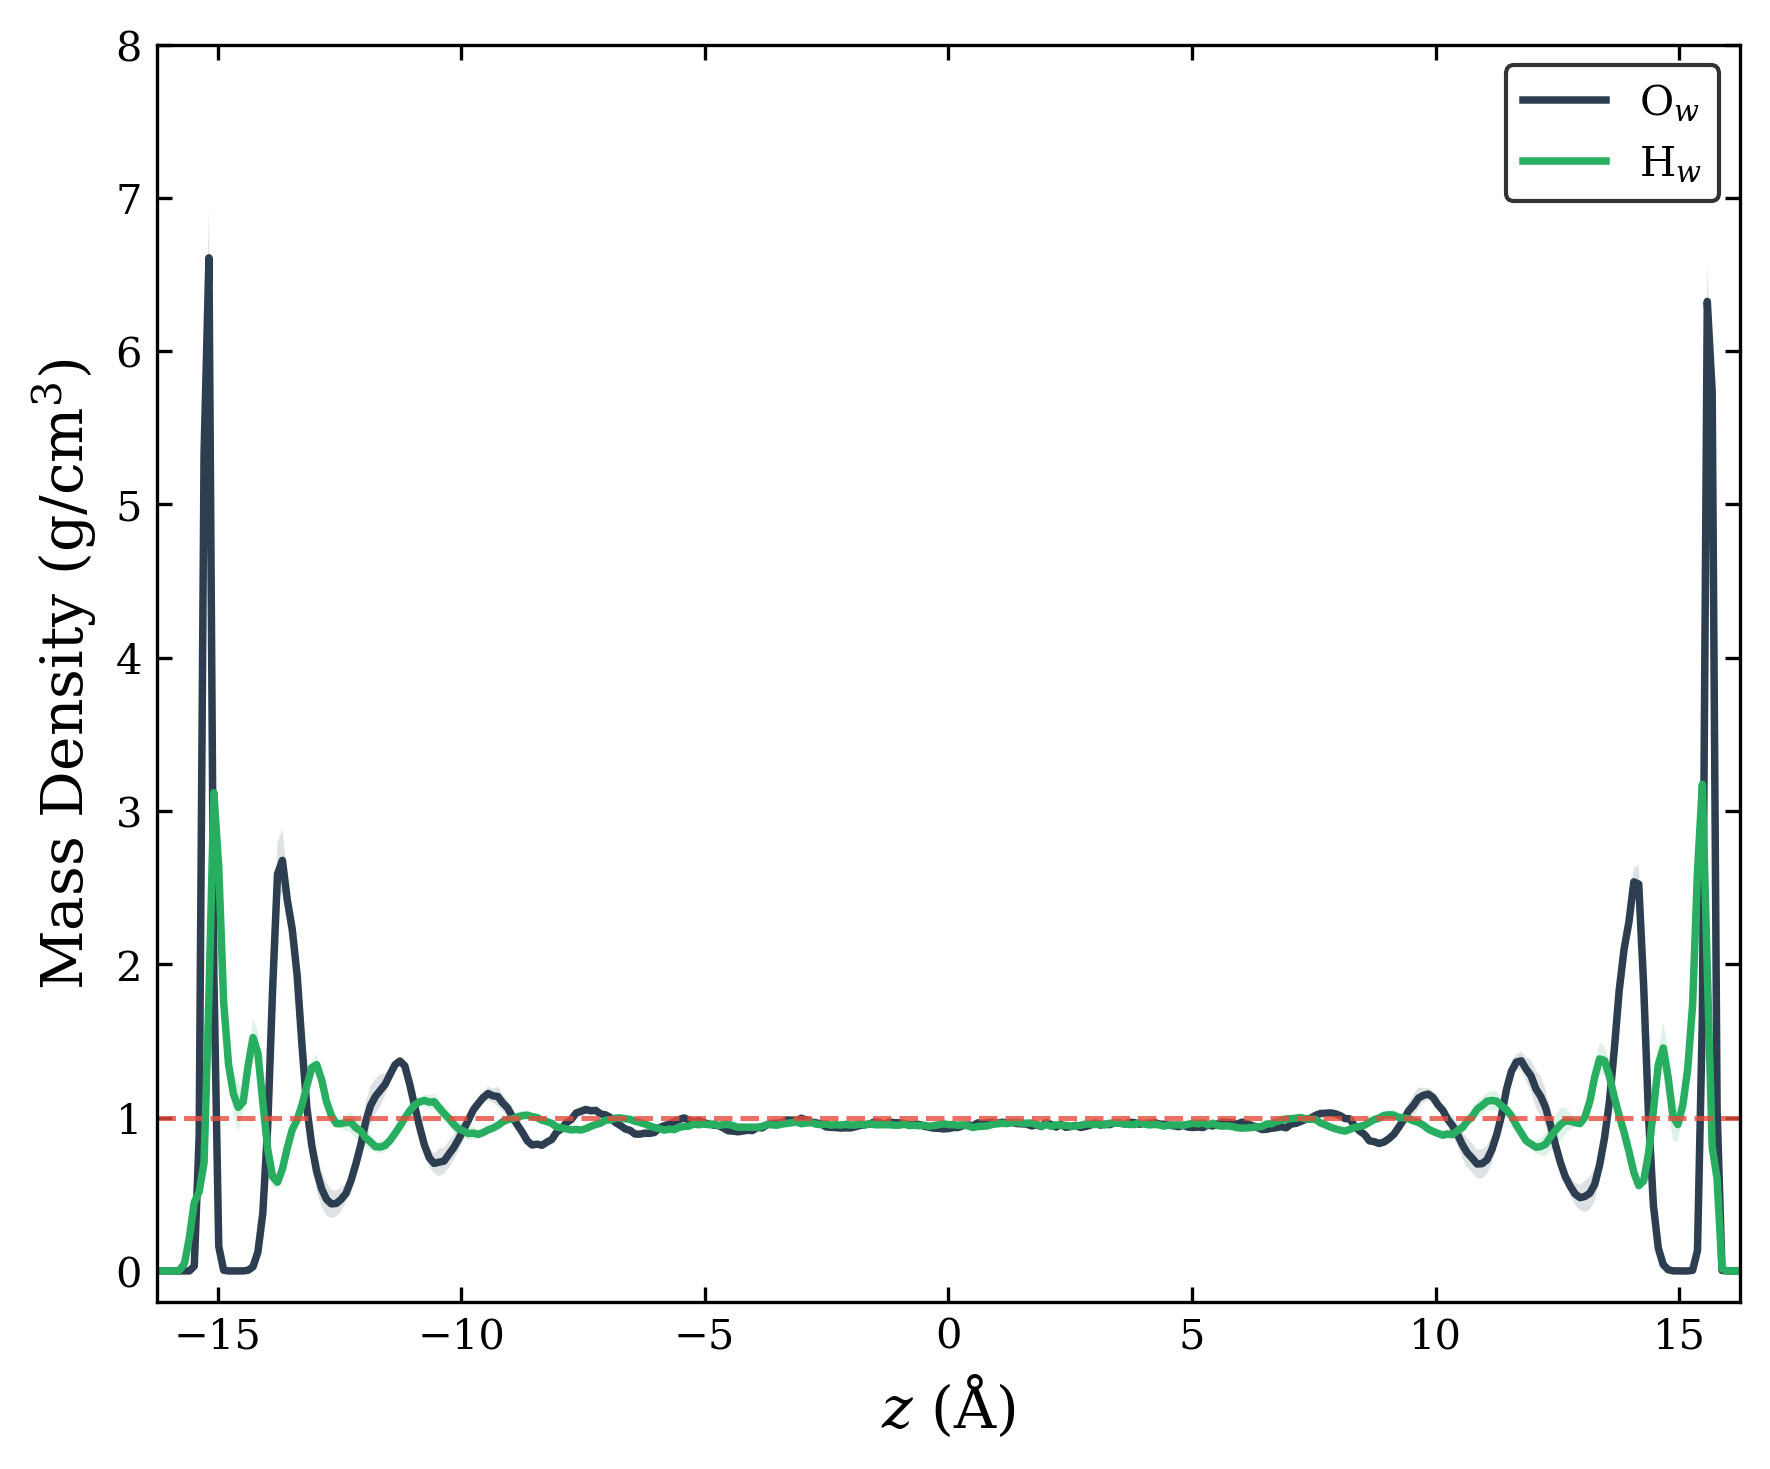

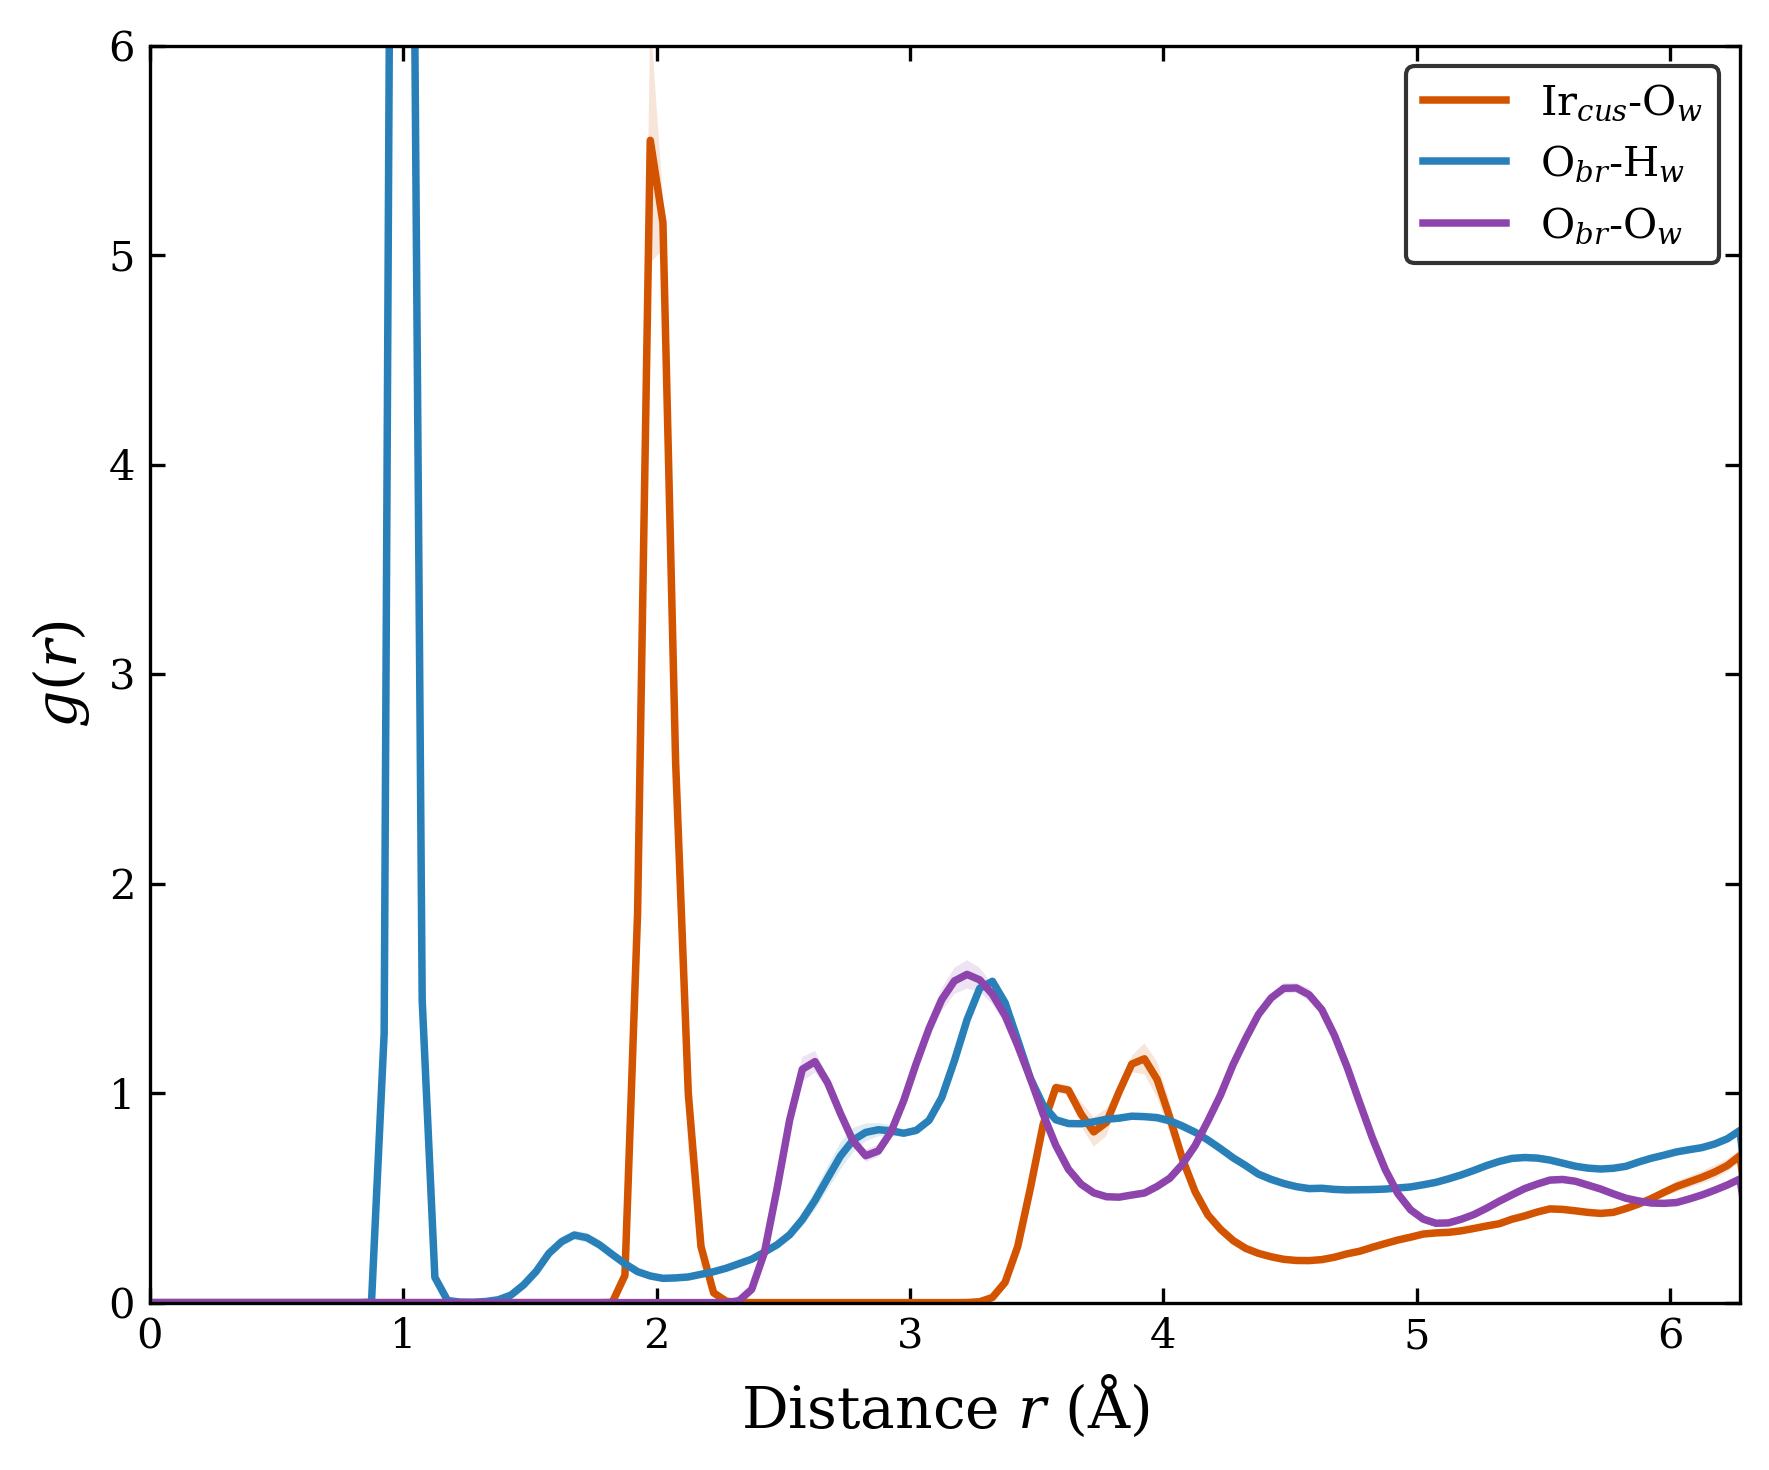

In [5]:
# --- Load Processed Data ---
data = np.load(base_dir+'simulation_results.npz', allow_pickle=True)
m_label = str(data['m_symbol'])

# Formatting settings
plt.rcParams["font.family"] = "serif"
plt.rcParams["mathtext.fontset"] = "dejavuserif"

# ###################################### PLOT 1: WATER DENSITY PROFILE ######################################
fig1, ax1 = plt.subplots(figsize=(6, 5), dpi=300)

ow_all = np.array(data['ow_y'], dtype='float')
hw_all = np.array(data['hw_y'], dtype='float')

# Calculate mean and standard deviation across DP models
ow_avg, ow_std = np.mean(ow_all, axis=0), np.std(ow_all, axis=0)
hw_avg, hw_std = np.mean(hw_all, axis=0), np.std(hw_all, axis=0)
z_axis = data['bins_z'][0]

# Plot Oxygen and Hydrogen density
ax1.plot(z_axis, ow_avg, lw=1.8, color='#2C3E50', label=r'O$_{w}$')
ax1.plot(z_axis, hw_avg, lw=1.8, color='#27AE60', label=r'H$_{w}$')

# Add shaded error bands (Standard Deviation)
ax1.fill_between(z_axis, ow_avg-ow_std, ow_avg+ow_std, color='#2C3E50', alpha=0.15, edgecolor='none')
ax1.fill_between(z_axis, hw_avg-hw_std, hw_avg+hw_std, color='#27AE60', alpha=0.15, edgecolor='none')

# Bulk water reference line (1.0 g/cm^3)
ax1.axhline(1.0, ls='--', lw=1.2, color='#E74C3C', alpha=0.8)

ax1.set_xlabel(r'$z$ ($\mathrm{\AA}$)', fontsize=14)
ax1.set_ylabel(r'Mass Density (g/cm$^3$)', fontsize=14)
ax1.set_xlim(-16.25, 16.25)
ax1.set_ylim(-0.2, 8.0)
ax1.legend(loc='upper right', frameon=True, edgecolor='black')
ax1.tick_params(direction='in', top=True, right=True)

plt.tight_layout()
plt.show()

# ###################################### PLOT 2: RDF COMPARISON ######################################
fig2, ax2 = plt.subplots(figsize=(6, 5), dpi=300)

r_axis = data['rd'][0]
rdf_sets = [
    (data['g_mow'], '#D35400', f'{m_label}$_{{cus}}$-O$_w$'),
    (data['g_osh'], '#2980B9', r'O$_{br}$-H$_w$'),
    (data['g_osow'], '#8E44AD', r'O$_{br}$-O$_w$')
]

for g_data, color, label in rdf_sets:
    avg = np.mean(g_data, axis=0)
    std = np.std(g_data, axis=0)
    ax2.plot(r_axis, avg, lw=1.8, color=color, label=label)
    ax2.fill_between(r_axis, avg-std, avg+std, color=color, alpha=0.15, edgecolor='none')

ax2.set_xlabel(r'Distance $r$ ($\mathrm{\AA}$)', fontsize=14)
ax2.set_ylabel(r'$g(r)$', fontsize=14)
ax2.set_xlim(0, 6.275)
ax2.set_ylim(0, 6.0)
ax2.legend(loc='upper right', frameon=True, edgecolor='black')
ax2.tick_params(direction='in', top=True, right=True)

plt.tight_layout()
plt.show()

In [ ]:
################################################################################
# DETAILED SUMMARY: SURFACE ANALYSIS, WATER DYNAMICS & SURVIVAL KINETICS
################################################################################
#
# 1. STRUCTURAL CHARACTERIZATION & SITE MAPPING:
#    - Geometric Analysis: Parses .extxyz trajectories to find the interface.
#    - Metal Surface (M_sur): Uses Z-coordinate thresholds to find surface atoms.
#    - Adsorption Mapping: Defines "Adsorbed Oxygen" (O_adb) as water oxygens 
#      within 2.5 Å of a surface metal atom (Cus site). 
#    - Stoichiometry Filter: Uses the oxide formula (e.g., IrO2) to separate 
#      lattice oxygens from water oxygens.
#
# 2. DISSOCIATION KINETICS (Chemical State Tracking):
#    - Coordination Check: For every snapshot, the script uses a Neighbor List 
#      algorithm (cutoff = 1.2 Å) to count Hydrogens bonded to each O_adb.
#    - State Classification:
#        * 1 H neighbor  -> Dissociated State (Surface Hydroxyl / OH).
#        * 2 H neighbors -> Intact State (Molecular Water / H2O).
#    - Population Statistics: Calculates the instantaneous % of dissociation 
#      across the entire surface for every time step.
#
# 3. SURVIVAL PROBABILITY (P(t) Calculation):
#    - Continuous Tracking: Uses set intersections to check if a specific 
#      molecule stays in the SAME state (OH or H2O) over a time interval (tau).
#    - Time-Correlation: Averages these correlations across all possible 
#      time origins (t_0) to improve statistical sampling.
#    - Decay Profile: Produces a curve starting at 1.0 (100% survival) and 
#      decaying toward 0 as molecules dissociate, recombine, or desorb.
#
# 4. RESIDENCE TIME & ENSEMBLE AVERAGING (tau):
#    - Integration: Calculates the mean residence time (tau) by integrating 
#      the area under the P(t) curve using the Trapezoidal rule.
#    - Multi-Model Statistics: Runs the entire logic for 'N' different DP 
#      models to provide a "Mean ± Standard Deviation" result.
#
# 5. VISUALIZATION & UNCERTAINTY:
#    - Survival Plots: Compares the stability of OD vs. D2O states.
#    - Fraction Plots: Shows the percentage of dissociation over the 
#      simulation time to check for equilibrium.
#    - Error Bands: Shaded regions represent the standard deviation across 
#      different models, highlighting where the simulation is most reliable.
#
################################################################################

In [6]:
# --- Start the execution timer ---
overall_start_time = time.perf_counter()

#################################### USER INPUT & INITIALIZATION ####################################

m = input("Enter the chemical symbol for the Metal Atom (e.g., Ti): ")
s = int(input("Enter the stoichiometry of Oxygen (e.g., TiO2 = 2): "))
dp = int(input("Enter the number of DP models: "))
base_dir = input("Enter the base directory path: ")

# Settings for analysis
analysis_stride = 10  # Analyze every 10th frame from the file
modelz = list(range(1, dp + 1))

# Containers for cross-model averaging
all_surv_oh, all_surv_h2o, all_times_survival = [], [], []
all_diss_frac, all_intact_frac = [], []
detected_dt_ns = 0.0

for model_num in modelz:
    print(f"\n--- Processing Model {model_num} ---")
    traj_file = f'{base_dir}/{model_num}/iro2_water_concat.extxyz'

    try:
        # Read first two frames to AUTOMATE the time-step detection
        sample = io.read(traj_file, index=':2')
        # Formula: (Time between saved frames) * (Our analysis stride) / 1000 (ps to ns)
        try:
            dt_file = sample[1].info['time'] - sample[0].info['time']
        except KeyError:
            dt_file = 0.05  # Fallback: 0.0005ps * 100 steps = 0.05 ps
            print("Time info not in header; using fallback 0.05 ps/frame.")
        
        detected_dt_ns = (dt_file * analysis_stride) / 1000 
        
        # Read trajectory using the stride
        traj = io.read(traj_file, index=slice(0, None, analysis_stride))
        atoms_init = traj[0] # Use the first frame of the current model for site ID
    except FileNotFoundError:
        print(f"Skipping Model {model_num}: File not found."); continue

    #################################### SITE IDENTIFICATION ####################################
    posn = atoms_init.get_positions()
    sym = atoms_init.get_chemical_symbols()
    
    # Categorize Z-positions to identify surface vs bulk
    m_z = sorted([pos[2] for s_i, pos in zip(sym, posn) if s_i == m])
    o_z_idx = [i for i, s_i in enumerate(sym) if s_i == 'O']
    o_z_vals = sorted([posn[i][2] for i in o_z_idx])

    # Find Top Surface Metal indices
    m_sur_idx = [i for i, s_i in enumerate(sym) if s_i == m and posn[i][2] >= max(m_z) - 1.5]
    
    # Find Bulk Oxygen indices based on stoichiometry
    o_bul_cutoff = o_z_vals[s*len(m_z)-1] if s*len(m_z)-1 < len(o_z_vals) else o_z_vals[-1]
    o_bul_idx = [i for i in o_z_idx if posn[i][2] <= o_bul_cutoff]

    # Identify Adsorbed Oxygen (O_adb) on CUS sites (Cutoff 2.5 Angstrom)
    o_adb_idx = []
    for i in m_sur_idx:
        for inh in o_z_idx:
            if inh not in o_bul_idx:
                if atoms_init.get_distance(i, inh, mic=True) <= 2.5:
                    if inh not in o_adb_idx: o_adb_idx.append(inh)
    o_adb_idx.sort()

    #################################### COORDINATION TRACKING ####################################
    indx_oh, indx_h2o = [], []
    frac_oh, frac_h2o = [], []
    num_ads = len(o_adb_idx)

    for frame in traj:
        frame.wrap()
        # Find H-neighbors (Cutoff 1.2 Angstrom for O-H bond)
        i_idx, _, _ = neighbor_list('ijd', frame, {('O', 'H'): 1.2}, self_interaction=False)
        o_h_counts = np.bincount(i_idx, minlength=len(frame))

        oh_frame, h2o_frame = [], []
        for idx in o_adb_idx:
            h_count = o_h_counts[idx]
            if h_count == 1: oh_frame.append(idx)   # 1 H = Dissociated (OH)
            elif h_count == 2: h2o_frame.append(idx) # 2 H = Molecular (H2O)
        
        indx_oh.append(oh_frame)
        indx_h2o.append(h2o_frame)
        frac_oh.append(100 * len(oh_frame) / num_ads if num_ads > 0 else 0)
        frac_h2o.append(100 * len(h2o_frame) / num_ads if num_ads > 0 else 0)

    #################################### SURVIVAL PROBABILITY ####################################
    oh_sets = [set(f) for f in indx_oh]
    h2o_sets = [set(f) for f in indx_h2o]
    num_f = len(oh_sets)
    # Calculate 101 points along the time-lag (tau) axis
    tau_range = np.linspace(0, num_f - 1, 101, dtype=int)
    
    s_oh, s_h2o = [], []
    for tau in tau_range:
        if tau == 0:
            s_oh.append(1.0); s_h2o.append(1.0)
        else:
            sig_oh, sig_h2o = [], []
            for j in range(num_f - tau):
                # Continuous Survival Logic: Intersection of all frames in the interval [j, j+tau]
                if oh_sets[j]:
                    sig_oh.append(len(set.intersection(*oh_sets[j:j+tau+1])) / len(oh_sets[j]))
                if h2o_sets[j]:
                    sig_h2o.append(len(set.intersection(*h2o_sets[j:j+tau+1])) / len(h2o_sets[j]))
            s_oh.append(np.mean(sig_oh) if sig_oh else 0)
            s_h2o.append(np.mean(sig_h2o) if sig_h2o else 0)

    # Store results for this specific DP model
    all_surv_oh.append(s_oh); all_surv_h2o.append(s_h2o)
    all_times_survival.append(tau_range * detected_dt_ns)
    all_diss_frac.append(frac_oh); all_intact_frac.append(frac_h2o)

# --- Save Results to NPZ File ---
np.savez(base_dir+'survival_fraction_results.npz', 
         m_symbol=m, times_surv=all_times_survival, surv_oh=all_surv_oh, 
         surv_h2o=all_surv_h2o, frac_oh=all_diss_frac, 
         frac_h2o=all_intact_frac, dt_ns=detected_dt_ns)

print(f"\nAnalysis complete. Data saved to survival_fraction_results.npz.")
print(f"Total time: {(time.perf_counter()-overall_start_time)/60:.2f} mins.")

Enter the chemical symbol for the Metal Atom (e.g., Ti):  Ir
Enter the stoichiometry of Oxygen (e.g., TiO2 = 2):  2
Enter the number of DP models:  3
Enter the base directory path:  /home/cmel3/Utkarsh/SuperComputer/Final_code_check/



--- Processing Model 1 ---
Time info not in header; using fallback 0.05 ps/frame.

--- Processing Model 2 ---
Time info not in header; using fallback 0.05 ps/frame.

--- Processing Model 3 ---
Time info not in header; using fallback 0.05 ps/frame.

Analysis complete. Data saved to survival_fraction_results.npz.
Total time: 42.08 mins.



--- Residence Time (tau) Summary ---
Average tau_OD:  0.298 +/- 0.114 ns
Average tau_D2O: 0.043 +/- 0.028 ns

--- Summary of Adsorbed Water Fractions ---
Avg. Dissociated Fraction (OD): 77.44% ± 6.48%
Avg. Molecular Fraction (D2O):  22.56% ± 6.48%


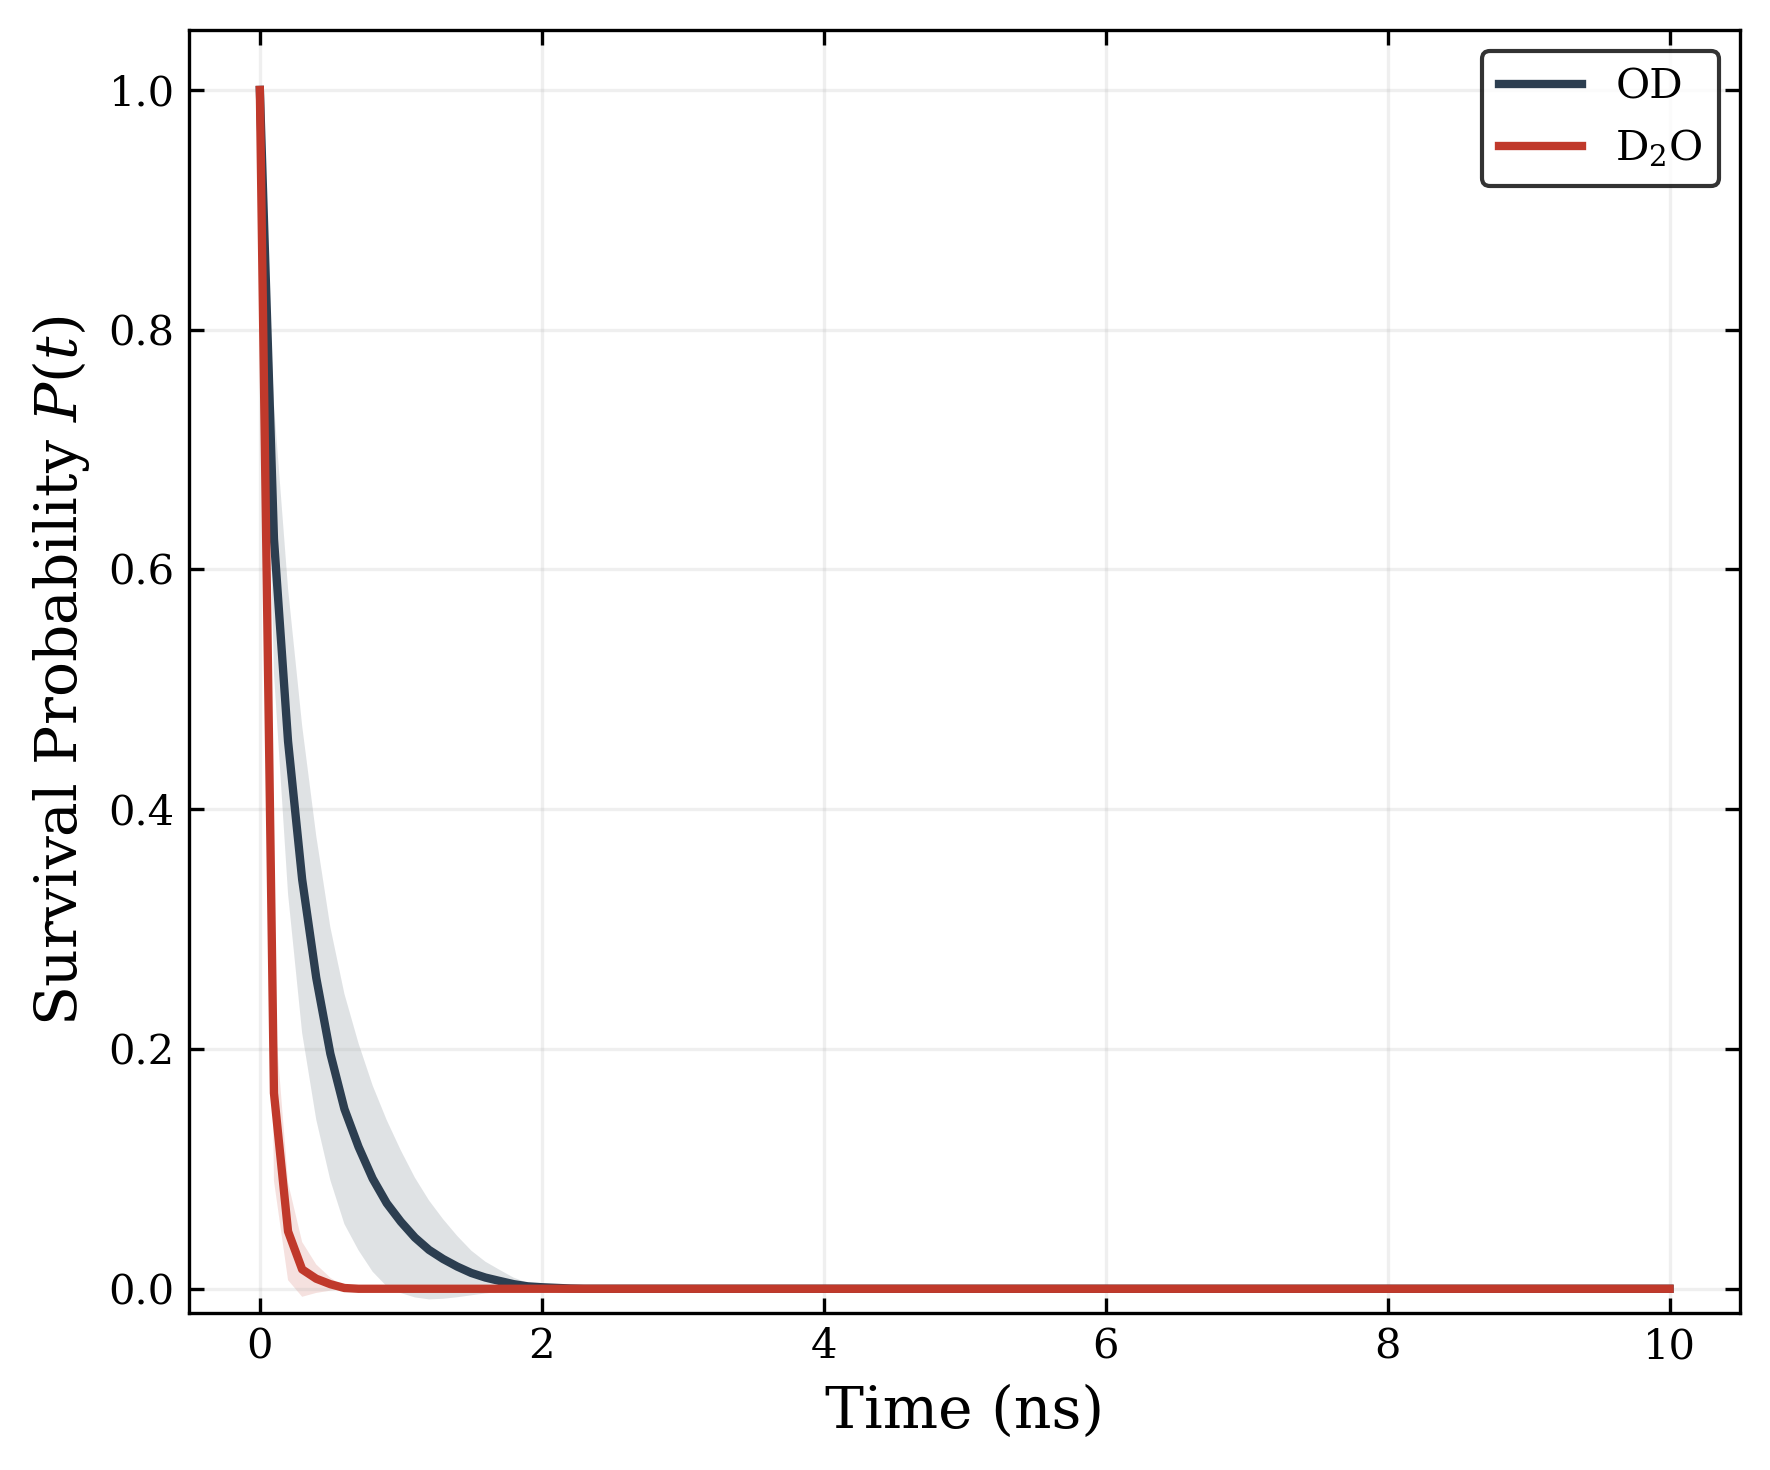

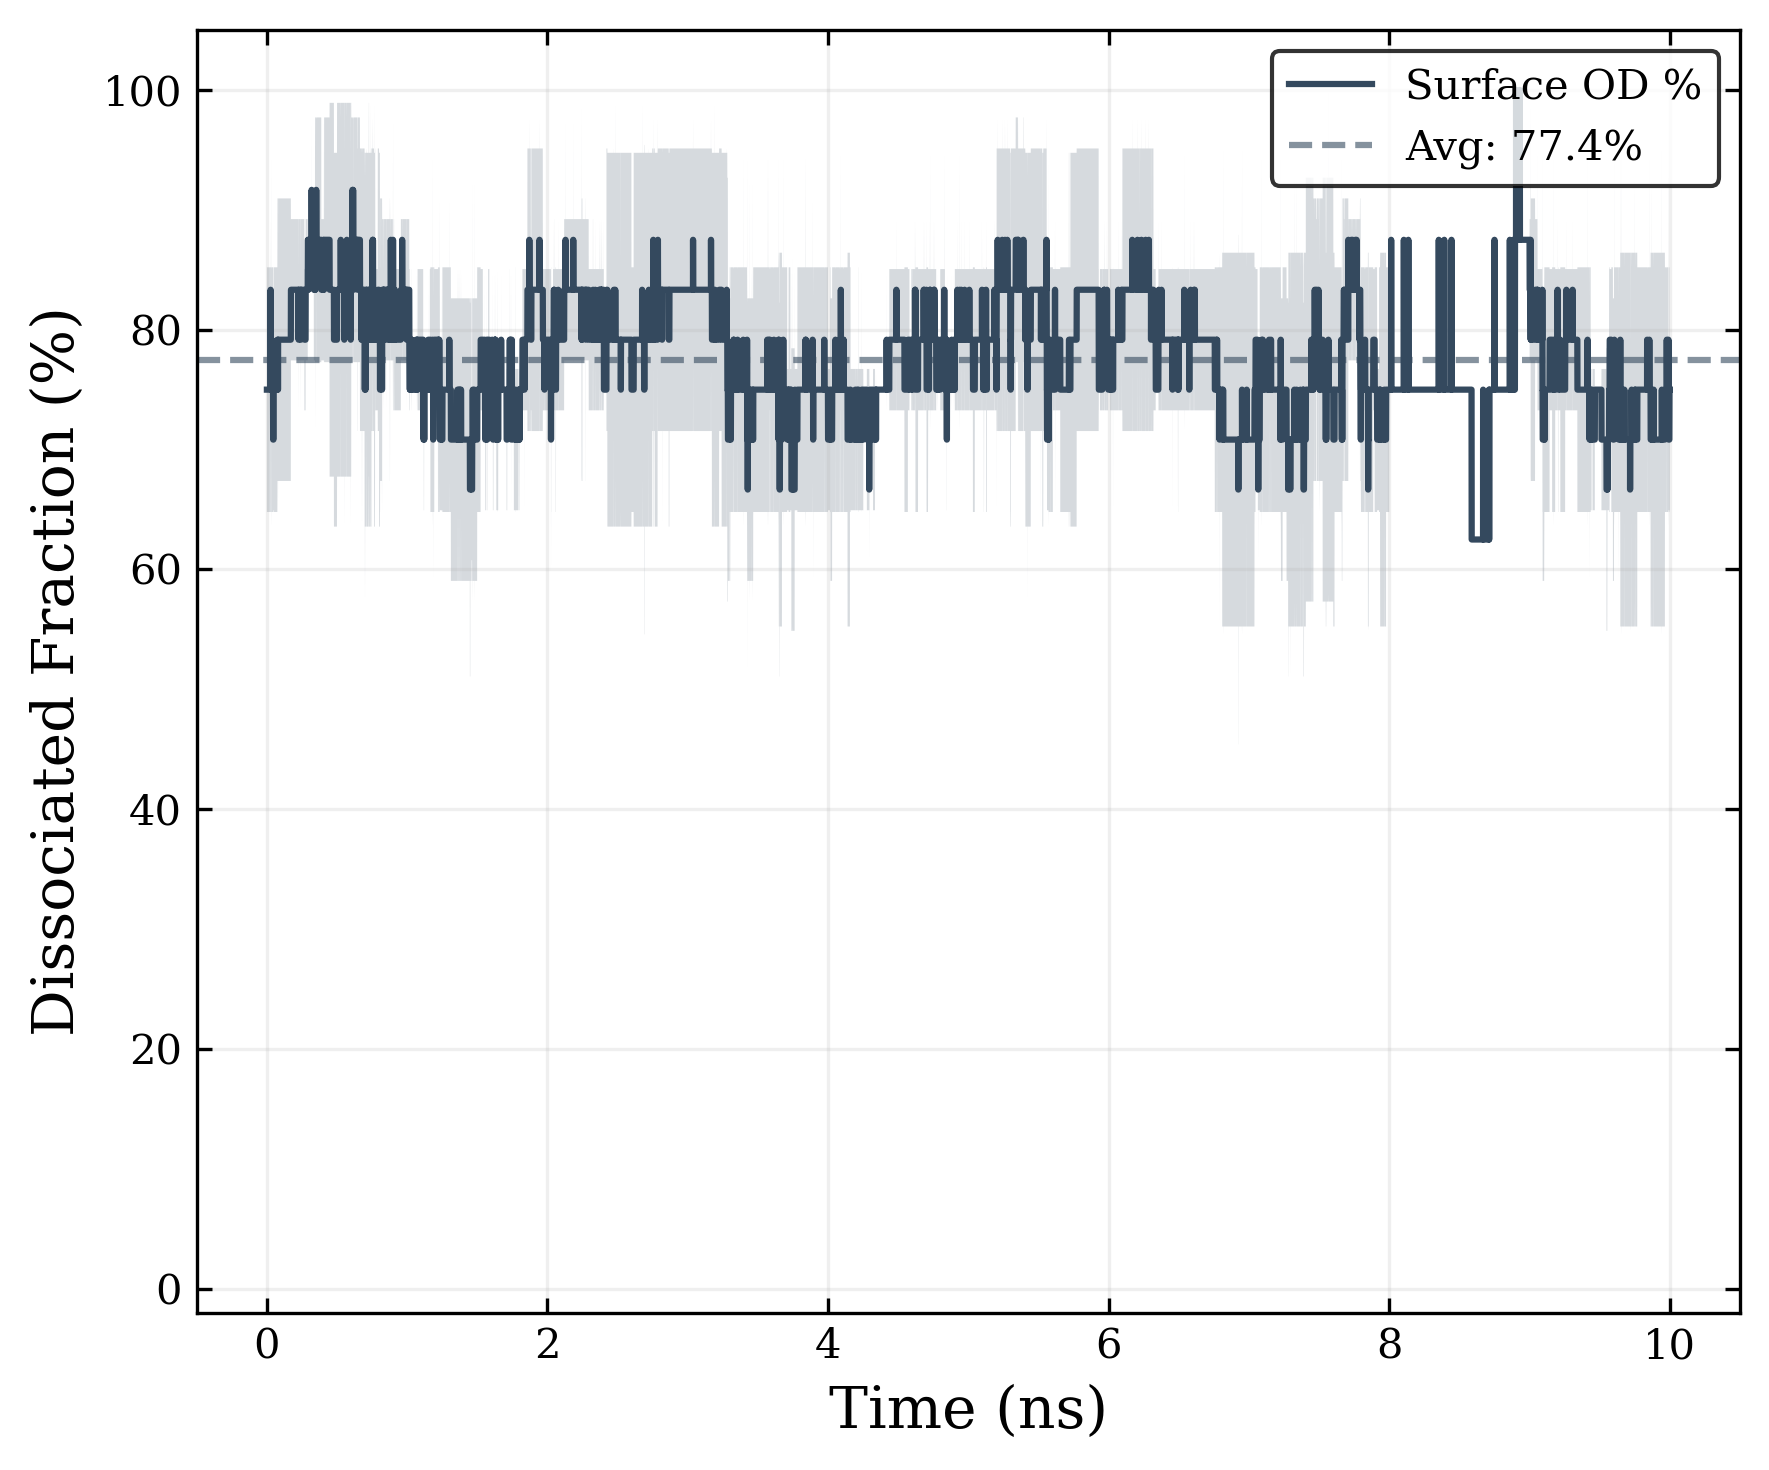

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# --- Load Data ---
# Note: Ensure 'survival_fraction_results.npz' is in the same folder or provide full path
data = np.load(base_dir+'survival_fraction_results.npz', allow_pickle=True)
m_label = str(data['m_symbol'])
dt_ns = data['dt_ns']

# Global Plot Settings
plt.rcParams["font.family"] = "serif"
plt.rcParams["mathtext.fontset"] = "dejavuserif"

# ################################## 1. RESIDENCE TIME (TAU) ##################################
def get_tau(surv, times):
    """Calculates residence time using the integral of the survival curve."""
    num = np.trapezoid(np.array(surv) * times, times)
    den = np.trapezoid(surv, times)
    return num / den if den > 1e-12 else 0.0

# Calculate Tau for every DP model
tau_oh_list = [get_tau(s, t) for s, t in zip(data['surv_oh'], data['times_surv'])]
tau_h2o_list = [get_tau(s, t) for s, t in zip(data['surv_h2o'], data['times_surv'])]

print(f"\n--- Residence Time (tau) Summary ---")
print(f"Average tau_OD:  {np.mean(tau_oh_list):.3f} +/- {np.std(tau_oh_list):.3f} ns")
print(f"Average tau_D2O: {np.mean(tau_h2o_list):.3f} +/- {np.std(tau_h2o_list):.3f} ns")

# ################################## 2. SURFACE FRACTIONS SUMMARY #############################
# Calculate the mean percentage for each model first, then the group average
model_means_diss = [np.mean(m_frac) for m_frac in data['frac_oh']]
model_means_intact = [np.mean(m_frac) for m_frac in data['frac_h2o']]

total_diss_avg = np.mean(model_means_diss)
total_diss_std = np.std(model_means_diss)

total_intact_avg = np.mean(model_means_intact)
total_intact_std = np.std(model_means_intact)

plus_minus = "\u00B1"
print("\n--- Summary of Adsorbed Water Fractions ---")
print(f"Avg. Dissociated Fraction (OD): {total_diss_avg:.2f}% {plus_minus} {total_diss_std:.2f}%")
print(f"Avg. Molecular Fraction (D2O):  {total_intact_avg:.2f}% {plus_minus} {total_intact_std:.2f}%")

# ################################## 3. SURVIVAL PROBABILITY PLOT #############################
fig1, ax1 = plt.subplots(figsize=(6, 5), dpi=300)
t_surv = data['times_surv'][0]

for s_data, color, lbl in [(data['surv_oh'], '#2c3e50', 'OD'), (data['surv_h2o'], '#c0392b', 'D$_2$O')]:
    avg = np.mean(s_data, axis=0)
    std = np.std(s_data, axis=0)
    ax1.plot(t_surv, avg, lw=2.0, color=color, label=lbl)
    ax1.fill_between(t_surv, avg-std, avg+std, color=color, alpha=0.15, edgecolor='none')

ax1.set_xlabel('Time (ns)', fontsize=14)
ax1.set_ylabel(r'Survival Probability $P(t)$', fontsize=14)
ax1.set_ylim(-0.02, 1.05)
ax1.tick_params(direction='in', top=True, right=True)
ax1.legend(frameon=True, edgecolor='black')
ax1.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# ################################## 4. SURFACE FRACTION PLOT #################################
fig2, ax2 = plt.subplots(figsize=(6, 5), dpi=300)
max_len = len(data['frac_oh'][0])
t_frac = np.arange(max_len) * dt_ns

# Calculate the mean and std across DP models for the trend line
f_avg = np.mean(data['frac_oh'], axis=0)
f_std = np.std(data['frac_oh'], axis=0)

ax2.plot(t_frac, f_avg, lw=1.5, color='#34495e', label='Surface OD %')
ax2.fill_between(t_frac, f_avg-f_std, f_avg+f_std, color='#34495e', alpha=0.2, edgecolor='none')

# Add a reference line for the total average
ax2.axhline(total_diss_avg, color='#34495e', linestyle='--', alpha=0.6, label=f'Avg: {total_diss_avg:.1f}%')

ax2.set_xlabel('Time (ns)', fontsize=14)
ax2.set_ylabel('Dissociated Fraction (%)', fontsize=14)
ax2.set_ylim(-2, 105)
ax2.tick_params(direction='in', top=True, right=True)
ax2.legend(frameon=True, edgecolor='black', loc='upper right')
ax2.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Data for Ir loaded successfully.
Consolidated Plot saved as 'full_analysis_presentation.png'


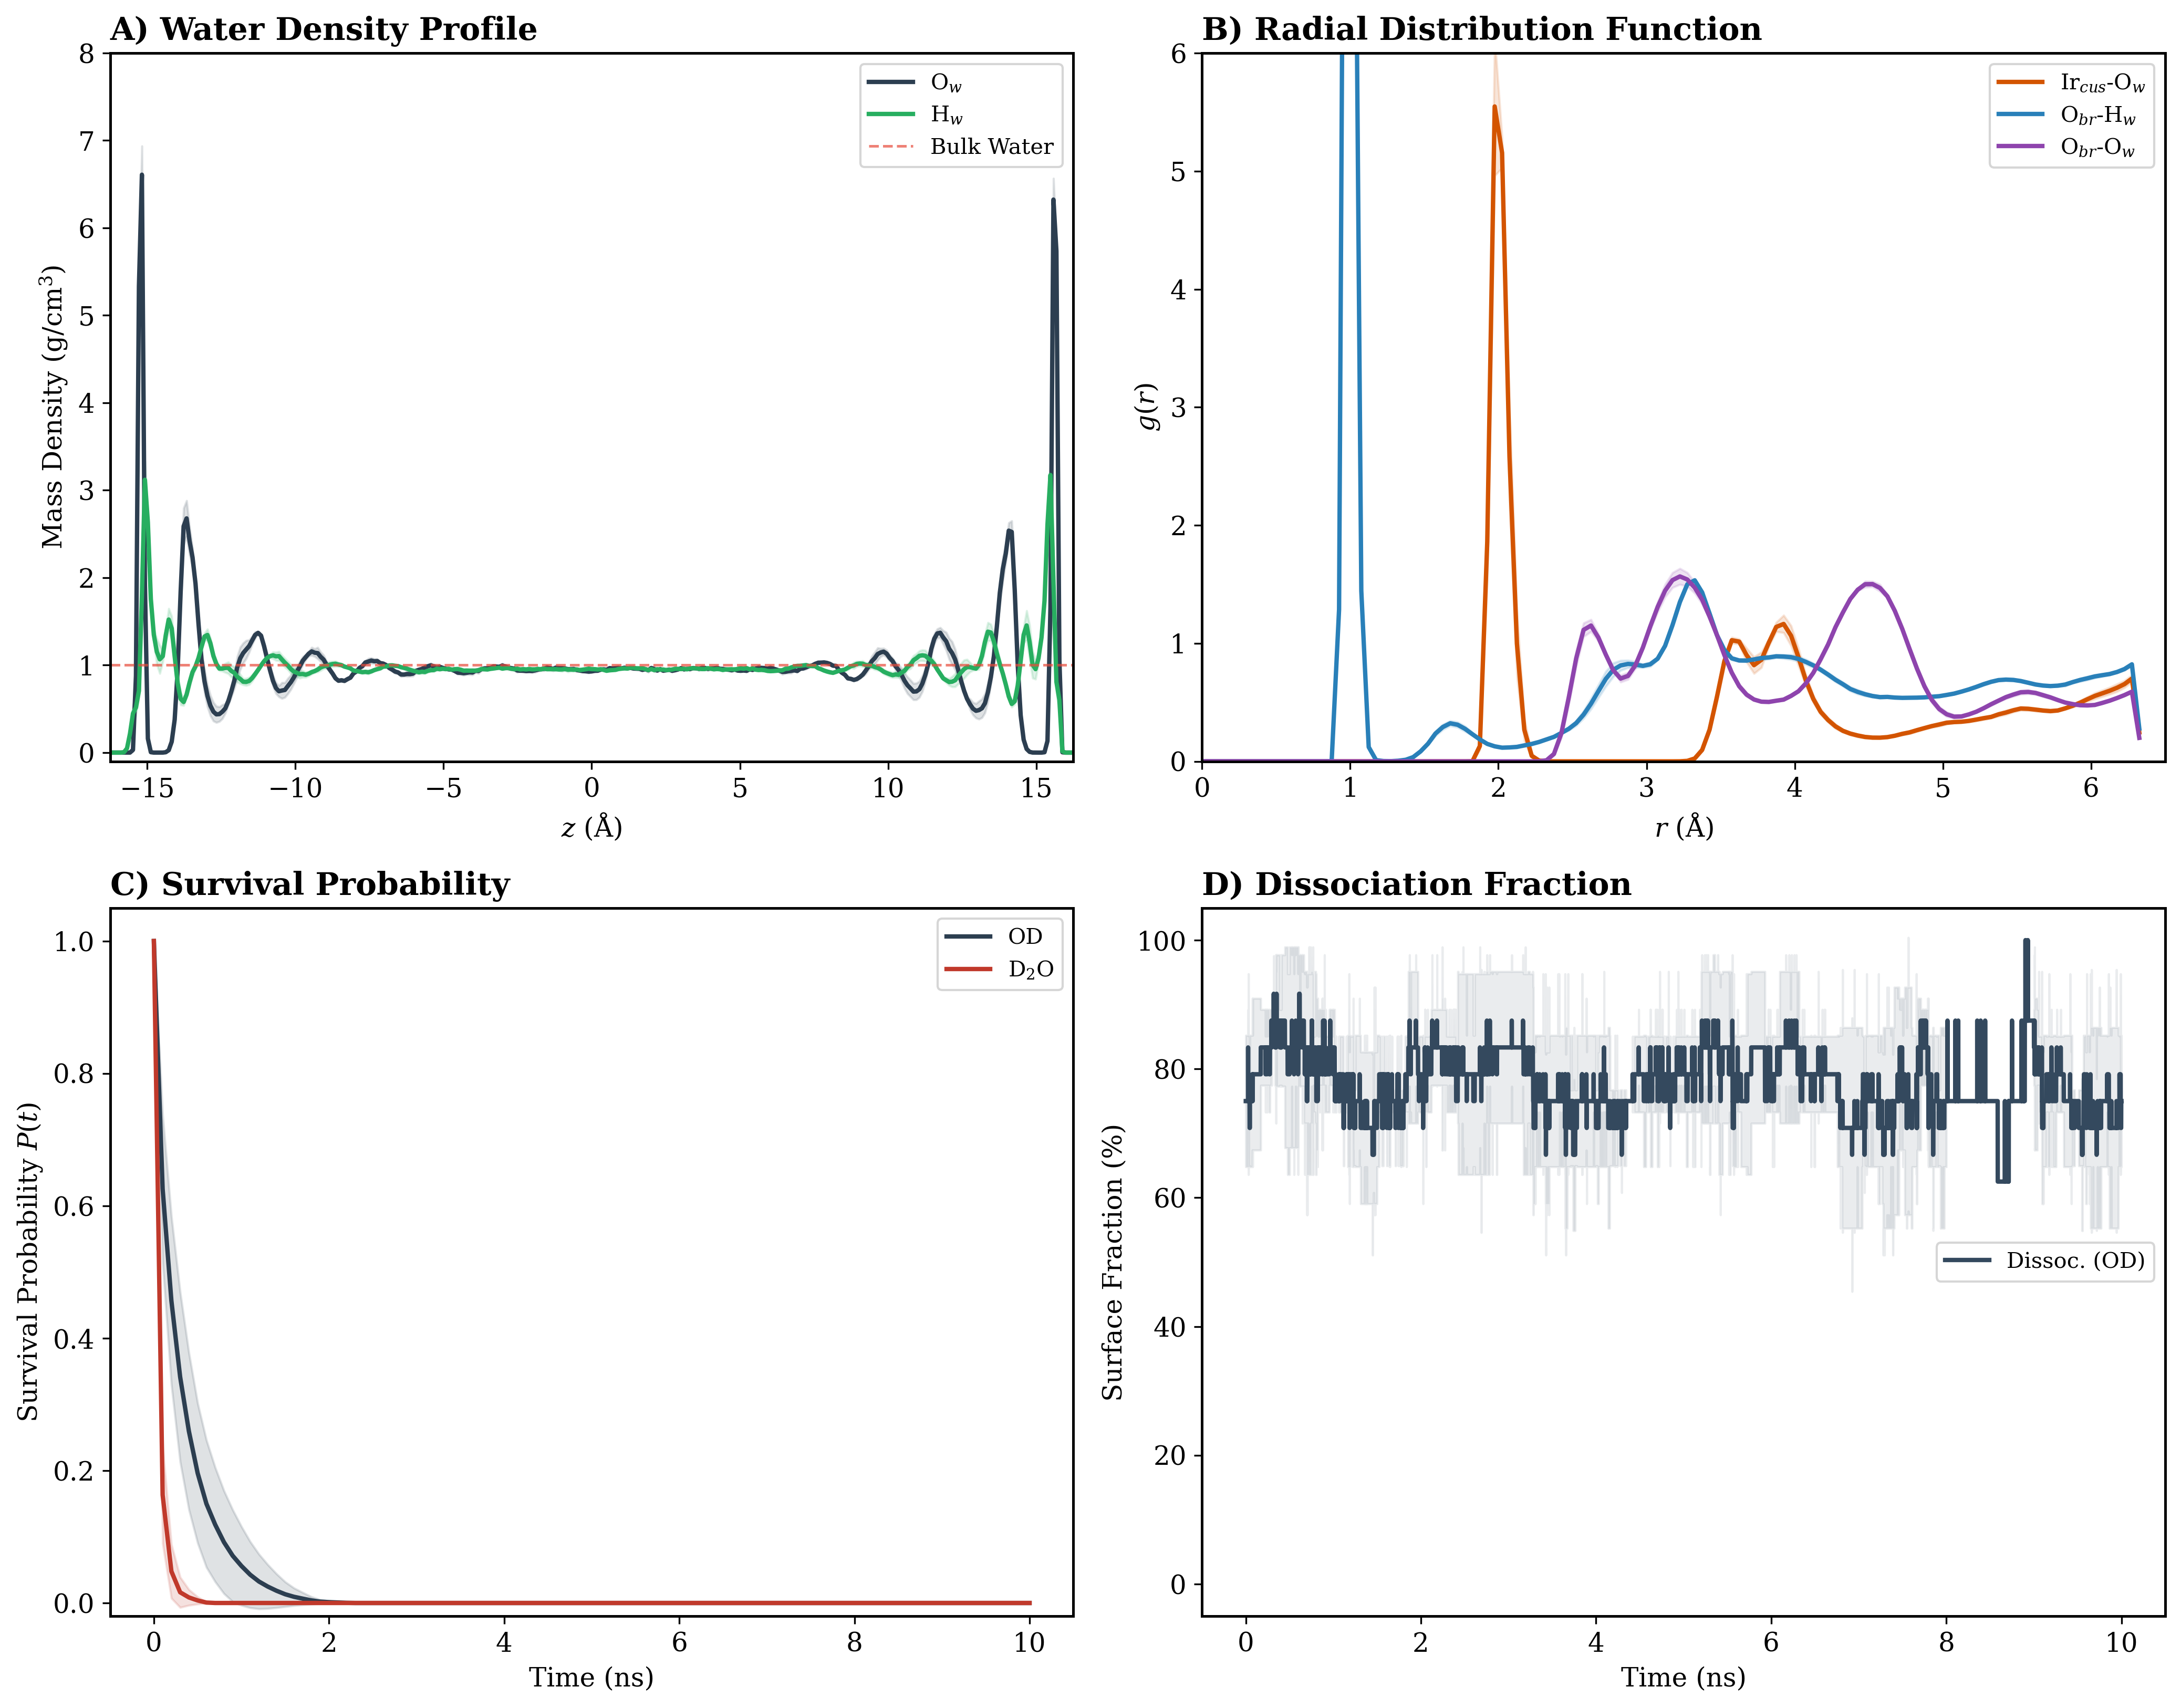


--- QUICK STATS FOR SLIDES ---
Surface Dissociation: 77.4% OD vs 22.6% D2O
Residence Time OD:  0.298 ns
Summary report written to 'summary_report.txt'


In [11]:
import numpy as np
import matplotlib.pyplot as plt
import os

# --- 1. LOAD ALL DATA ---
try:
    dens_data = np.load('simulation_results.npz', allow_pickle=True)
    surv_data = np.load('survival_fraction_results.npz', allow_pickle=True)
    m_symbol = str(dens_data['m_symbol'])
    dt_ns = surv_data['dt_ns']
    print(f"Data for {m_symbol} loaded successfully.")
except FileNotFoundError as e:
    print(f"Error: Could not find one of the data files. {e}")
    exit()

# Global Styling
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "dejavuserif",
    "font.size": 12,
    "axes.linewidth": 1.2
})

# Create a 2x2 Grid for the presentation
fig, axs = plt.subplots(2, 2, figsize=(14, 11), dpi=300)
((ax_dens, ax_rdf), (ax_surv, ax_frac)) = axs

# -------------------------------------------------------------------------
# PANEL A: WATER DENSITY PROFILE (Top Left)
# -------------------------------------------------------------------------
z_axis = dens_data['bins_z'][0]
for d_key, color, lbl in [('ow_y', '#2C3E50', r'O$_{w}$'), ('hw_y', '#27AE60', r'H$_{w}$')]:
    avg = np.mean(dens_data[d_key], axis=0)
    std = np.std(dens_data[d_key], axis=0)
    ax_dens.plot(z_axis, avg, lw=2, color=color, label=lbl)
    ax_dens.fill_between(z_axis, avg-std, avg+std, color=color, alpha=0.15)

ax_dens.axhline(1.0, ls='--', lw=1.2, color='#E74C3C', alpha=0.7, label='Bulk Water')
ax_dens.set_xlabel(r'$z$ ($\mathrm{\AA}$)'); ax_dens.set_ylabel(r'Mass Density (g/cm$^3$)')
ax_dens.set_xlim(-16.25, 16.25); ax_dens.set_ylim(-0.1, 8.0)
ax_dens.legend(loc='upper right', frameon=True, fontsize=10)
ax_dens.set_title("A) Water Density Profile", loc='left', fontweight='bold')

# -------------------------------------------------------------------------
# PANEL B: RADIAL DISTRIBUTION FUNCTION (Top Right)
# -------------------------------------------------------------------------
r_axis = dens_data['rd'][0]
rdf_list = [
    (dens_data['g_mow'], '#D35400', f'{m_symbol}$_{{cus}}$-O$_w$'),
    (dens_data['g_osh'], '#2980B9', r'O$_{br}$-H$_w$'),
    (dens_data['g_osow'], '#8E44AD', r'O$_{br}$-O$_w$')
]
for g_data, color, lbl in rdf_list:
    avg, std = np.mean(g_data, axis=0), np.std(g_data, axis=0)
    ax_rdf.plot(r_axis, avg, lw=2, color=color, label=lbl)
    ax_rdf.fill_between(r_axis, avg-std, avg+std, color=color, alpha=0.15)

ax_rdf.set_xlabel(r'$r$ ($\mathrm{\AA}$)'); ax_rdf.set_ylabel(r'$g(r)$')
ax_rdf.set_xlim(0, 6.5); ax_rdf.set_ylim(0, 6.0)
ax_rdf.legend(loc='upper right', frameon=True, fontsize=10)
ax_rdf.set_title("B) Radial Distribution Function", loc='left', fontweight='bold')

# -------------------------------------------------------------------------
# PANEL C: SURVIVAL PROBABILITY (Bottom Left)
# -------------------------------------------------------------------------
t_surv = surv_data['times_surv'][0]
for s_key, color, lbl in [('surv_oh', '#2C3E50', 'OD'), ('surv_h2o', '#C0392B', 'D$_2$O')]:
    avg, std = np.mean(surv_data[s_key], axis=0), np.std(surv_data[s_key], axis=0)
    ax_surv.plot(t_surv, avg, lw=2, color=color, label=lbl)
    ax_surv.fill_between(t_surv, avg-std, avg+std, color=color, alpha=0.15)

ax_surv.set_xlabel('Time (ns)'); ax_surv.set_ylabel(r'Survival Probability $P(t)$')
ax_surv.set_ylim(-0.02, 1.05); ax_surv.legend(frameon=True, fontsize=10)
ax_surv.set_title("C) Survival Probability", loc='left', fontweight='bold')

# -------------------------------------------------------------------------
# PANEL D: DISSOCIATION FRACTION (Bottom Right)
# -------------------------------------------------------------------------
max_len = len(surv_data['frac_oh'][0])
t_frac = np.arange(max_len) * dt_ns
f_oh_avg = np.mean(surv_data['frac_oh'], axis=0)
f_oh_std = np.std(surv_data['frac_oh'], axis=0)

ax_frac.plot(t_frac, f_oh_avg, lw=2, color='#34495E', label='Dissoc. (OD)')
ax_frac.fill_between(t_frac, f_oh_avg - f_oh_std, f_oh_avg + f_oh_std, color='#34495E', alpha=0.1)

ax_frac.set_xlabel('Time (ns)'); ax_frac.set_ylabel('Surface Fraction (%)')
ax_frac.set_ylim(-5, 105); ax_frac.legend(loc='center right', frameon=True, fontsize=10)
ax_frac.set_title("D) Dissociation Fraction", loc='left', fontweight='bold')

# Clean up layout and save
plt.tight_layout()
plt.savefig('full_analysis_presentation.png', bbox_inches='tight')
print("Consolidated Plot saved as 'full_analysis_presentation.png'")
plt.show()

# --- 5. CALCULATE FINAL STATISTICS & GENERATE REPORT ---
def get_tau(surv, times):
    num = np.trapezoid(np.array(surv) * times, times)
    den = np.trapezoid(surv, times)
    return num / den if den > 1e-12 else 0.0

# Residence Times
tau_od_list = [get_tau(s, t) for s, t in zip(surv_data['surv_oh'], surv_data['times_surv'])]
tau_d2o_list = [get_tau(s, t) for s, t in zip(surv_data['surv_h2o'], surv_data['times_surv'])]

# Fractions
model_means_diss = [np.mean(m) for m in surv_data['frac_oh']]
model_means_molec = [np.mean(m) for m in surv_data['frac_h2o']]

avg_diss, std_diss = np.mean(model_means_diss), np.std(model_means_diss)
avg_molec, std_molec = np.mean(model_means_molec), np.std(model_means_molec)

# Save to File
with open('summary_report.txt', 'w') as f:
    f.write(f"=== FINAL ANALYSIS REPORT: {m_symbol} ===\n\n")
    f.write(f"1. SURFACE SPECIATION:\n")
    f.write(f"   - Avg. Dissociated (OD): {avg_diss:.2f}% +/- {std_diss:.2f}%\n")
    f.write(f"   - Avg. Molecular (D2O):  {avg_molec:.2f}% +/- {std_molec:.2f}%\n")
    f.write(f"   - Combined Total:        {avg_diss + avg_molec:.2f}%\n\n")
    
    f.write(f"2. RESIDENCE TIMES (TAU):\n")
    f.write(f"   - tau_OD:  {np.mean(tau_od_list):.4f} +/- {np.std(tau_od_list):.4f} ns\n")
    f.write(f"   - tau_D2O: {np.mean(tau_d2o_list):.4f} +/- {np.std(tau_d2o_list):.4f} ns\n\n")
    
print("\n--- QUICK STATS FOR SLIDES ---")
print(f"Surface Dissociation: {avg_diss:.1f}% OD vs {avg_molec:.1f}% D2O")
print(f"Residence Time OD:  {np.mean(tau_od_list):.3f} ns")
print(f"Summary report written to 'summary_report.txt'")